<a href="https://colab.research.google.com/github/torcodex/Time-Series-Practice/blob/main/Time_Series_Arima_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import pandas as pd
from prophet import Prophet
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error

In [2]:
url ='https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv'

df = pd.read_csv(url)
df

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
...,...,...
139,1960-08,606
140,1960-09,508
141,1960-10,461
142,1960-11,390


In [3]:
df.duplicated().sum()

np.int64(0)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Month       144 non-null    object
 1   Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


In [5]:
df['Month'] = pd.to_datetime(df['Month'])
df_c = df.copy()
df.set_index('Month', inplace=True)
df

,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1960-08-01,606
1960-09-01,508
1960-10-01,461


In [8]:
df_c.rename(columns={'Month': 'ds', 'Passengers': 'y'}, inplace=True)
df_c

,ds,y
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121
...,...,...
139,1960-08-01,606
140,1960-09-01,508
141,1960-10-01,461
142,1960-11-01,390


In [6]:
df.isna().sum()

,0
Passengers,0


In [54]:
result = adfuller(df.dropna())
result[1]

/tmp/ipykernel_556/3630789406.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df.dropna())


0.991880243437641

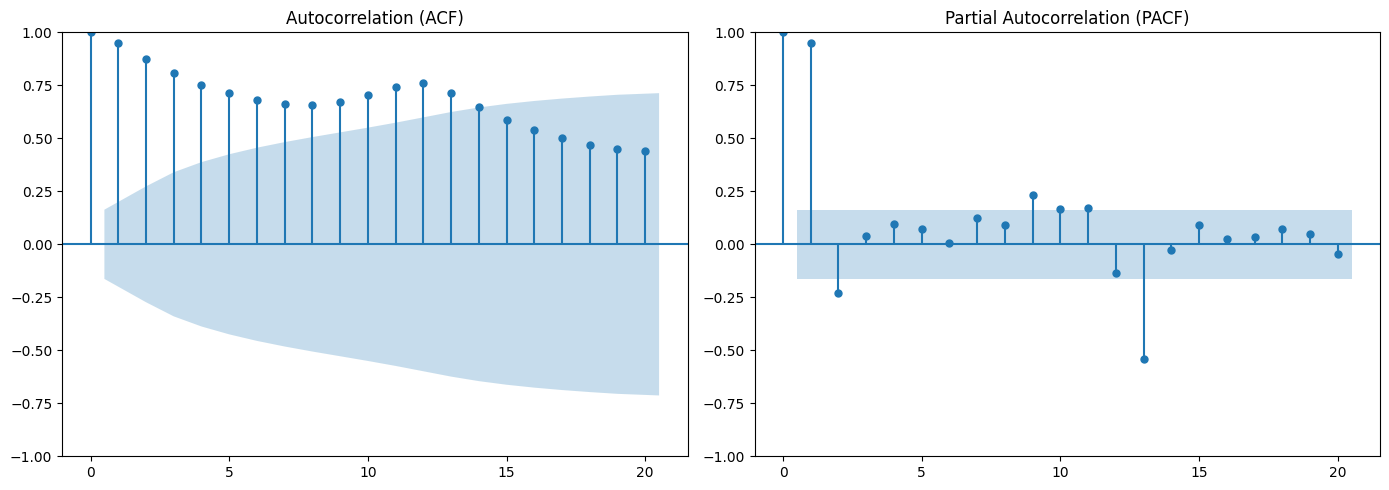

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(df, lags=20, ax=axes[0], title='Autocorrelation (ACF)')

plot_pacf(df, lags=20, ax=axes[1], method='ywm', title='Partial Autocorrelation (PACF)')

plt.tight_layout()
plt.show()

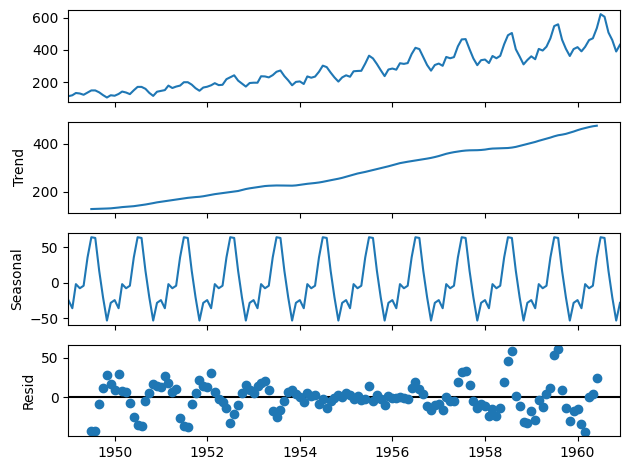

In [56]:
result = seasonal_decompose(df, model="additive", period=12)
result.plot()
plt.show()

In [37]:
training, testing = df_c[:-12], df_c[-12:]

In [38]:
training

,ds,y
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121
...,...,...
127,1959-08-01,559
128,1959-09-01,463
129,1959-10-01,407
130,1959-11-01,362


In [39]:
m = Prophet()
m.fit(training)

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [40]:
future = m.make_future_dataframe(periods=12,freq='MS')
future.tail()

,ds
139,1960-08-01
140,1960-09-01
141,1960-10-01
142,1960-11-01
143,1960-12-01


In [41]:
forecast = m.predict(future)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()

,ds,yhat,yhat_lower,yhat_upper
139,1960-08-01,527.291766,501.204020,552.337220
140,1960-09-01,486.118197,462.084866,512.835148
141,1960-10-01,452.436742,426.768483,478.777373
142,1960-11-01,422.627034,395.225406,447.416642
143,1960-12-01,447.903040,419.672520,473.749018


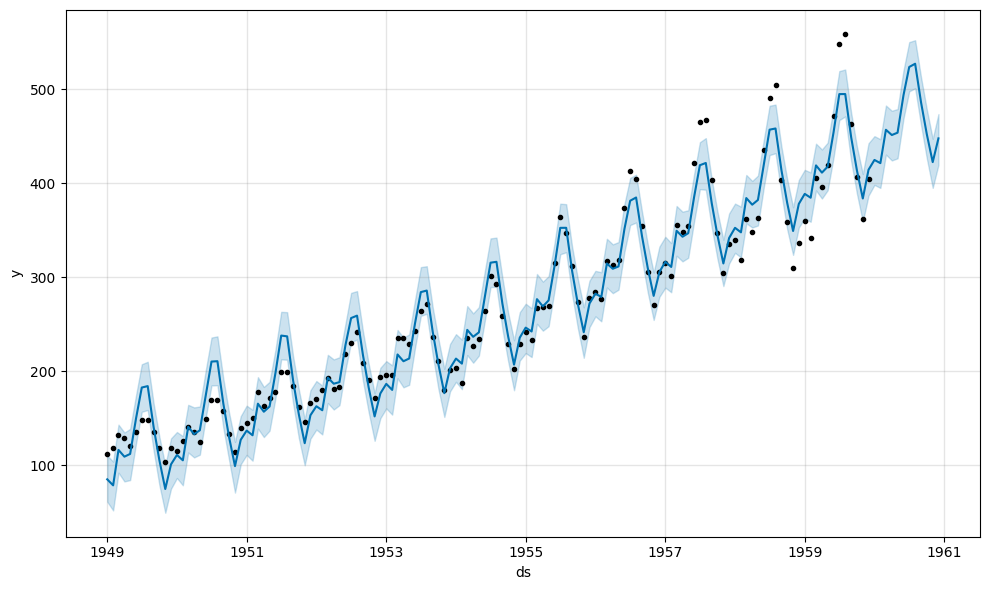

In [42]:
fig1 = m.plot(forecast)

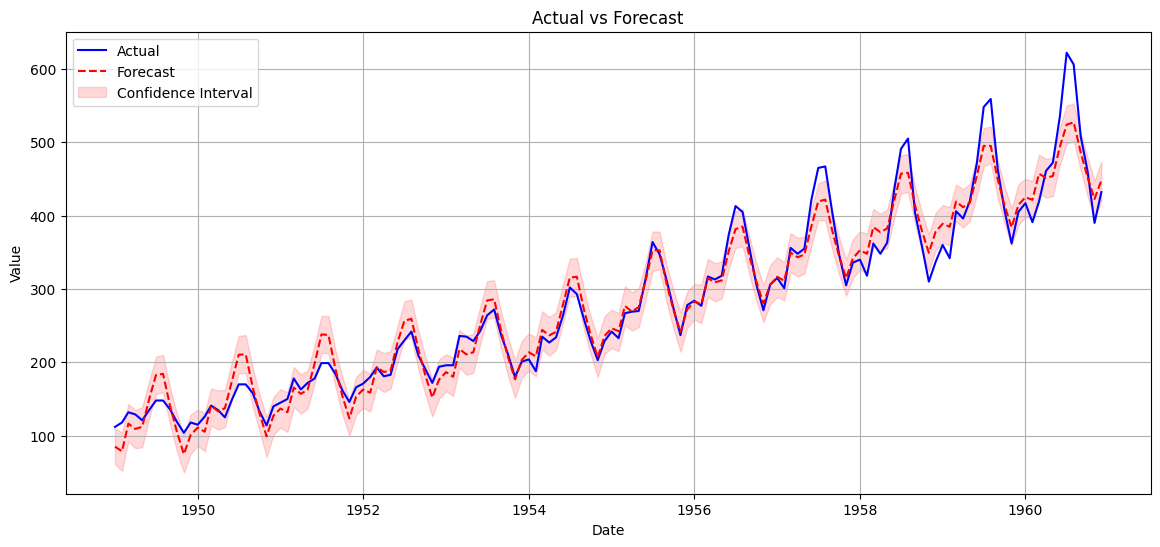

In [43]:
# Create comparison DataFrame using df_c which contains 'ds' and 'y'
comparison = forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].merge(
    df_c[['ds', 'y']],
    on='ds',
    how='left'
)

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(comparison['ds'], comparison['y'],
         label='Actual', color='blue')

plt.plot(comparison['ds'], comparison['yhat'],
         label='Forecast', color='red', linestyle='--')

plt.fill_between(
    comparison['ds'],
    comparison['yhat_lower'],
    comparison['yhat_upper'],
    color='red',
    alpha=0.15,
    label='Confidence Interval'
)

plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Actual vs Forecast')
plt.legend()
plt.grid(True)
plt.show()

In [48]:
predictions = forecast[['ds','yhat','yhat_lower','yhat_upper']].tail(12)
comparison = testing.merge(predictions, on='ds', how='left')
comparison

,ds,y,yhat,yhat_lower,yhat_upper
0,1960-01-01,417,424.941448,398.382943,450.256948
1,1960-02-01,391,421.560899,395.161326,447.010433
2,1960-03-01,419,457.038329,430.626568,482.867009
3,1960-04-01,461,451.464014,424.411261,477.265784
4,1960-05-01,472,453.950218,426.661917,479.104535
5,1960-06-01,535,493.794382,468.955688,520.085982
6,1960-07-01,622,523.845770,497.949883,550.313616
7,1960-08-01,606,527.291766,501.204020,552.337220
8,1960-09-01,508,486.118197,462.084866,512.835148
9,1960-10-01,461,452.436742,426.768483,478.777373


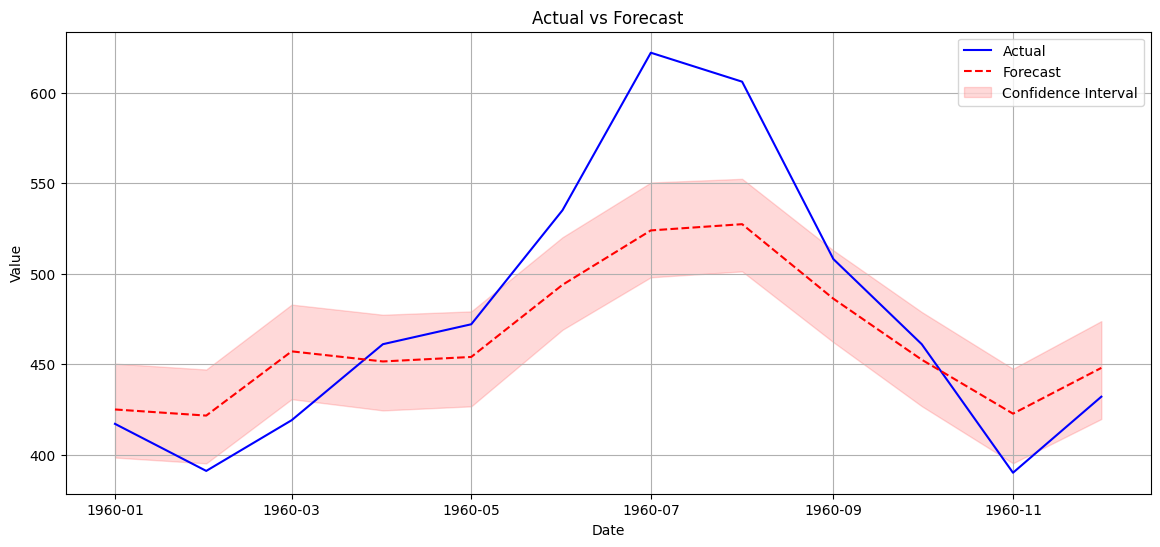

In [49]:
plt.figure(figsize=(14, 6))

plt.plot(comparison['ds'], comparison['y'],
         label='Actual', color='blue')

plt.plot(comparison['ds'], comparison['yhat'],
         label='Forecast', color='red', linestyle='--')

plt.fill_between(
    comparison['ds'],
    comparison['yhat_lower'],
    comparison['yhat_upper'],
    color='red',
    alpha=0.15,
    label='Confidence Interval'
)

plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Actual vs Forecast')
plt.legend()
plt.grid(True)
plt.show()

In [50]:
eval = comparison.dropna(subset=['y'])

In [51]:
mse = mean_squared_error(eval['y'], eval['yhat'])
mae = mean_absolute_error(eval['y'], eval['yhat'])
rmse = root_mean_squared_error(eval['y'], eval['yhat'])

print(f'MSE: {mse}')
print(f'MAE: {mae}')
print(f'RMSE: {rmse}')

MSE: 1854.7828169687727
MAE: 33.43080500103388
RMSE: 43.06718956431651


In [67]:
train_size = int(len(df) * 0.8)
train, test = df[:train_size], df[train_size:]

In [92]:
model = ARIMA(train, order=(2, 1, 7))
fitted_model = model.fit()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [93]:
print(fitted_model.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(2, 1, 7)   Log Likelihood                -506.867
Date:                Fri, 13 Nov 2026   AIC                           1033.734
Time:                        08:11:01   BIC                           1061.096
Sample:                    01-01-1949   HQIC                          1044.839
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7112      0.145      4.903      0.000       0.427       0.996
ar.L2         -0.3137      0.151     -2.076      0.038      -0.610      -0.018
ma.L1         -0.4226      3.330     -0.127      0.8

In [94]:
forecast_steps = len(test)
forecast = fitted_model.get_forecast(steps=forecast_steps)
forecast_mean = forecast.predicted_mean
conf_int = forecast.conf_int()

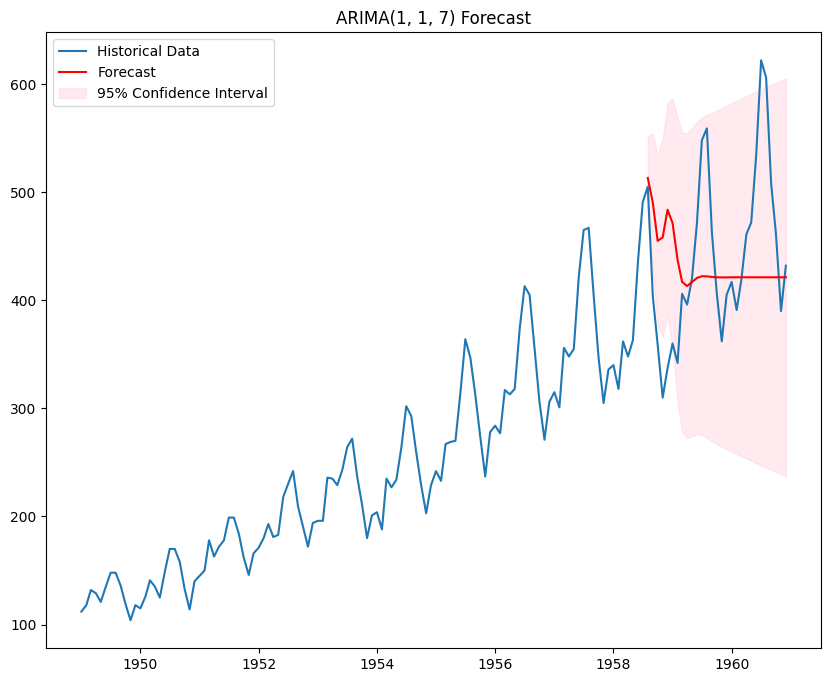

In [95]:
plt.figure(figsize=(10, 8))
plt.plot(df, label='Historical Data')
plt.plot(forecast_mean.index, forecast_mean, color='red', label='Forecast')
plt.fill_between(
    forecast_mean.index,
    conf_int.iloc[:, 0],
    conf_int.iloc[:, 1],
    color='pink',
    alpha=0.3,
    label='95% Confidence Interval',
)
plt.title('ARIMA(1, 1, 7) Forecast')
plt.legend()
plt.show()

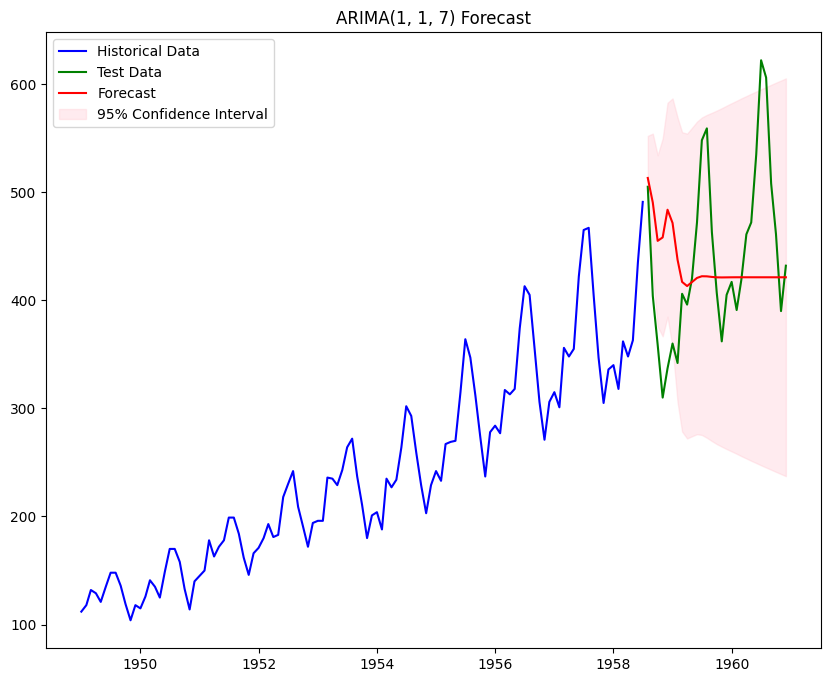

In [96]:
plt.figure(figsize=(10, 8))
plt.plot(train, label='Historical Data', color='blue')
plt.plot(test, label='Test Data', color='green')
plt.plot(forecast_mean.index, forecast_mean, color='red', label='Forecast')
plt.fill_between(
    forecast_mean.index,
    conf_int.iloc[:, 0],
    conf_int.iloc[:, 1],
    color='pink',
    alpha=0.3,
    label='95% Confidence Interval',
)
plt.title('ARIMA(1, 1, 7) Forecast')
plt.legend()
plt.show()

In [80]:
diff = df - df.shift(1)
diff

,Passengers
Month,
1949-01-01,NaN
1949-02-01,6.0
1949-03-01,14.0
1949-04-01,-3.0
1949-05-01,-8.0
...,...
1960-08-01,-16.0
1960-09-01,-98.0
1960-10-01,-47.0


In [81]:
diff_res = adfuller(diff.dropna())
diff_res[1]

/tmp/ipykernel_556/3765254390.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  diff_res = adfuller(diff.dropna())


0.05421329028382478

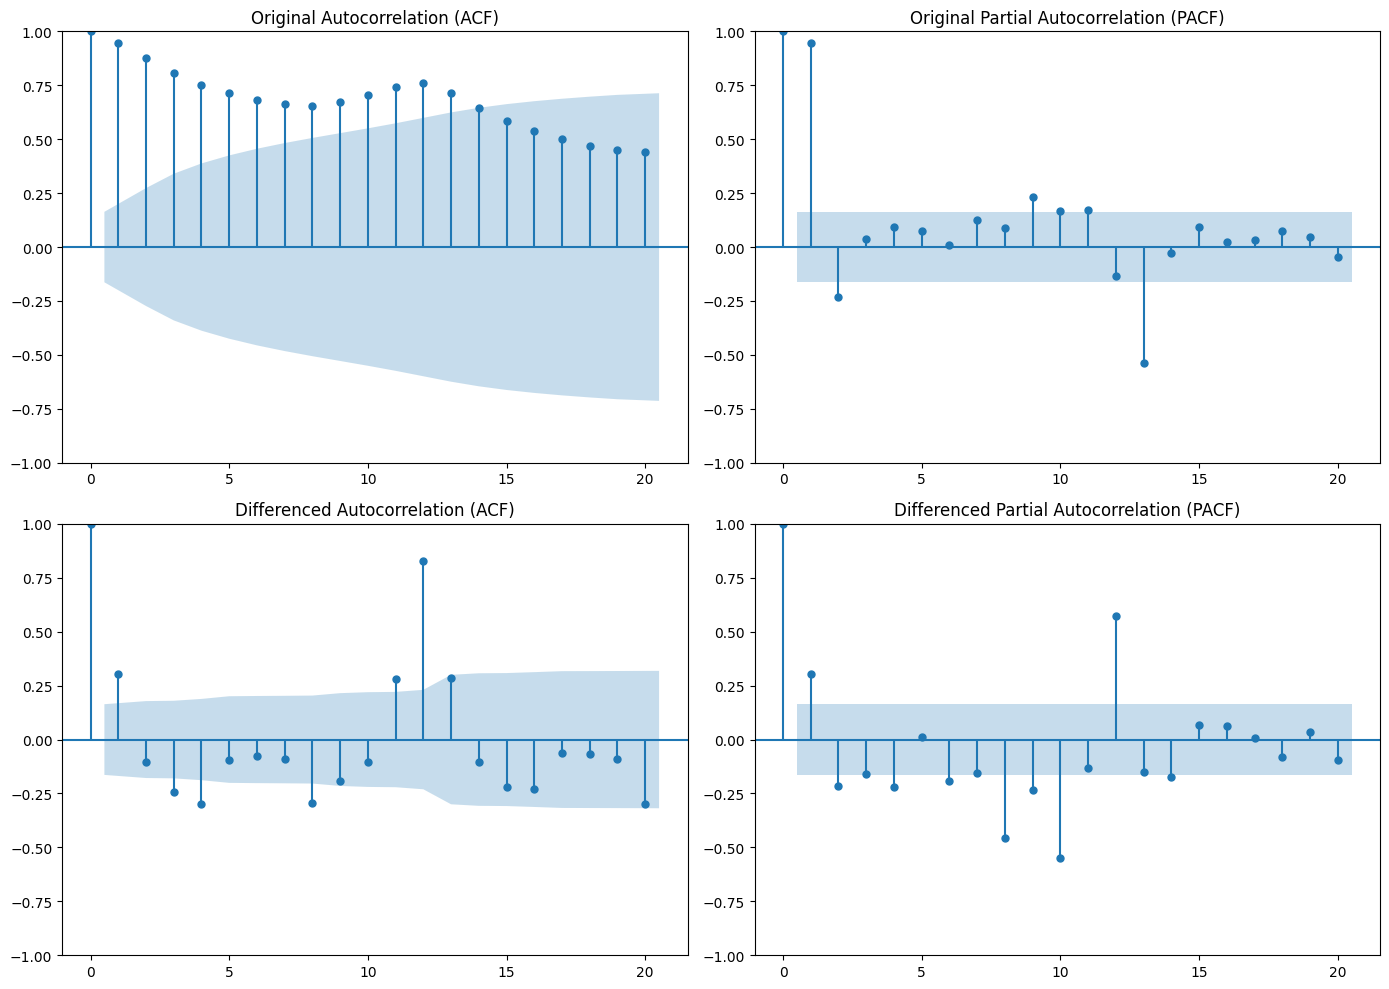

In [82]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot ACF and PACF for original data (df)
plot_acf(df, lags=20, ax=axes[0, 0], title='Original Autocorrelation (ACF)')
plot_pacf(df, lags=20, ax=axes[0, 1], method='ywm', title='Original Partial Autocorrelation (PACF)')

# Plot ACF and PACF for differenced data (diff - dropping NaN)
plot_acf(diff.dropna(), lags=20, ax=axes[1, 0], title='Differenced Autocorrelation (ACF)')
plot_pacf(diff.dropna(), lags=20, ax=axes[1, 1], method='ywm', title='Differenced Partial Autocorrelation (PACF)')

plt.tight_layout()
plt.show()